# Decomposing Trans-Compartmental Plasma-to-CSF Tau Partitioning Across the Alzheimer's Continuum (ADNI)

**Complete Audited & Reproducible Pipeline (v2 — CSF Dilution Control + Joint Parallel Mediation + Schoenfeld PH Validation)**
This notebook executes the full multi-modal ADNI analysis ($N = 411$ unique matched CSF–Plasma participants), including:
1. Biological continuum stratification ($N=409$ classified across `CN Aβ−`, `CN Aβ+`, `MCI Aβ−`, `MCI Aβ+`, and `AD Dementia`) with Holm-adjusted pairwise Mann–Whitney post-hoc tests.
2. **CSF Dilution Decomposition:** Head-to-head PET-adjusted Ventricular Capacitance (`Vent/ICV%`) modeling comparing $\Delta Z_{\text{CN}}$, $Da_{\text{Tau}}$, identical-analyte $\kappa_{A\beta40}$, standalone $\ln(\text{Plasma p-tau217})$, and standalone $\ln(\text{CSF p-tau181})$ **before and after controlling for global CSF protein dilution (`ln CSF Aβ40`)**.
3. **Neuroimmune, Astrocytic, DTI, and Renal Anchoring:** CSF `sTREM2` ($N=101$), Quanterix plasma `GFAP` and `NfL` ($N=411$ total; $N=406$ paired with $Da_{\text{Tau}}$), white-matter DTI ($N=282$), and CKD-EPI 2021 `eGFR` ($N=125$).
4. **AD-Specific Cox Survival:** Median follow-up (IQR), Schoenfeld proportional hazards assumption checks, Harrell optimism-corrected bootstrap C-indices, and 2-year/4-year ROC AUCs.
5. **3-Way Joint Parallel Statistical Mediation (1,000x Bootstrap):** Comparing `Da_Tau`, standalone `Plasma p-tau217`, and `ln(CSF Aβ40)`-adjusted `Da_Tau` with `Plasma GFAP` and `MRI Vent/ICV%` co-modeled simultaneously.
6. **Cross-Phase Multi-Era Replication:** Legacy ADNI (`ADNI1/GO/2`, $N=136$) vs. Modern 3T Harmonized ADNI (`ADNI3`, $N=275$).


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import zscore, spearmanr, mannwhitneyu, kruskal
from statsmodels.stats.multitest import multipletests
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, proportional_hazard_test
from lifelines.utils import concordance_index
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

DATA_DIR = os.path.join('data-20261119T152706Z-1-001', 'data')
FIG_DIR = 'revised_figures'
os.makedirs(FIG_DIR, exist_ok=True)

csf_df    = pd.read_csv(os.path.join(DATA_DIR, 'UPENNBIOMK_ROCHE_ELECSYS_12Jul2026.csv'), low_memory=False)
plasma_df = pd.read_csv(os.path.join(DATA_DIR, 'UPENN_PLASMA_FUJIREBIO_QUANTERIX_12Jul2026.csv'), low_memory=False)
adnimerge = pd.read_csv(os.path.join(DATA_DIR, 'ADNIMERGE_02Jun2026(1).csv'), low_memory=False)
trem_df   = pd.read_csv(os.path.join(DATA_DIR, 'ADNI_HAASS_WASHU_LAB_12Jul2026.csv'), low_memory=False)
lab_df    = pd.read_csv(os.path.join(DATA_DIR, 'LABDATA_04Jun2026.csv'), low_memory=False)
dti_df    = pd.read_csv(os.path.join(DATA_DIR, 'DTIROI_ROBUSTMEAN_20Aug2026.csv'), low_memory=False)
amy_df    = pd.read_csv(os.path.join(DATA_DIR, 'UCBERKELEY_AMY_6MM.csv'), low_memory=False)
tau_df    = pd.read_csv(os.path.join(DATA_DIR, 'UCBERKELEY_TAU_6MM.csv'), low_memory=False)

print(f"Loaded CSF: {len(csf_df):,} | Plasma: {len(plasma_df):,} | ADNIMERGE: {len(adnimerge):,}")
print(f"Loaded sTREM2: {len(trem_df):,} | LABDATA: {len(lab_df):,} | DTI: {len(dti_df):,} | Amy-PET: {len(amy_df):,} | Tau-PET: {len(tau_df):,}")


Loaded CSF: 3,174 | Plasma: 2,298 | ADNIMERGE: 16,421
Loaded sTREM2: 1,878 | LABDATA: 2,463 | DTI: 2,572 | Amy-PET: 4,728 | Tau-PET: 2,489


In [2]:
def clean_num(x):
    if isinstance(x, str):
        x = x.replace('<', '').replace('>', '').strip()
    return pd.to_numeric(x, errors='coerce')

for d in [csf_df, plasma_df, trem_df, lab_df, dti_df, amy_df, tau_df]:
    d['RID'] = pd.to_numeric(d['RID'], errors='coerce')
    if 'VISCODE2' in d.columns:
        d['VISCODE2'] = d['VISCODE2'].astype(str).str.strip().str.lower()
    elif 'VISCODE' in d.columns:
        d['VISCODE2'] = d['VISCODE'].astype(str).str.strip().str.lower()

adnimerge['RID'] = pd.to_numeric(adnimerge['RID'], errors='coerce')
adnimerge['VISCODE2'] = adnimerge['VISCODE'].astype(str).str.strip().str.lower()

for col in ['PTAU', 'TAU', 'ABETA42', 'ABETA40']:
    csf_df[col + '_CSF'] = csf_df[col].apply(clean_num)

for col in ['pT217_F', 'AB42_F', 'AB40_F', 'GFAP_Q', 'NfL_Q']:
    plasma_df[col + '_clean'] = plasma_df[col].apply(clean_num)
    plasma_df.loc[plasma_df[col + '_clean'] <= 0, col + '_clean'] = np.nan

trem_df['sTREM2_CSF'] = trem_df['MSD_STREM2CORRECTED'].apply(clean_num)

# Contemporaneous visit-matched CSF–Plasma pairs
matched = pd.merge(csf_df, plasma_df, on=['RID', 'VISCODE2'], how='inner', suffixes=('_csf', '_plasma'))
n_pairs = len(matched)
matched['is_bl'] = (matched['VISCODE2'] == 'bl').astype(int)
matched = matched.sort_values(['RID', 'is_bl', 'EXAMDATE_csf'], ascending=[True, False, True]).drop_duplicates(subset=['RID'], keep='first').copy()

base_clin = adnimerge[adnimerge['VISCODE2'] == 'bl'].drop_duplicates(subset=['RID']).drop(columns=['VISCODE2']).copy()
df = pd.merge(matched, base_clin, on='RID', how='inner')

visit_cols = ['RID', 'VISCODE2', 'DX', 'ADAS13', 'MMSE', 'Ventricles', 'Hippocampus', 'ICV', 'WholeBrain']
visit_dx = adnimerge[visit_cols].drop_duplicates(subset=['RID', 'VISCODE2']).copy()
visit_dx.columns = ['RID', 'VISCODE2', 'DX_visit', 'ADAS13_visit', 'MMSE_visit', 'Ventricles_visit', 'Hippocampus_visit', 'ICV_visit', 'WholeBrain_visit']
df = pd.merge(df, visit_dx, on=['RID', 'VISCODE2'], how='left')

# Merge CSF sTREM2, PET, and LABDATA Creatinine
trem_visit = trem_df[['RID', 'VISCODE2', 'sTREM2_CSF']].dropna().drop_duplicates(subset=['RID', 'VISCODE2'])
df = pd.merge(df, trem_visit, on=['RID', 'VISCODE2'], how='left')

amy_sub = amy_df[['RID', 'CENTILOIDS']].dropna().groupby('RID', as_index=False)['CENTILOIDS'].mean().rename(columns={'CENTILOIDS': 'Amyloid_PET'})
tau_sub = tau_df[['RID', 'META_TEMPORAL_SUVR']].dropna().groupby('RID', as_index=False)['META_TEMPORAL_SUVR'].mean().rename(columns={'META_TEMPORAL_SUVR': 'Tau_PET'})
df = df.merge(amy_sub, on='RID', how='left').merge(tau_sub, on='RID', how='left')

lab_df['Creatinine'] = lab_df['RCT392'].apply(clean_num)
lab_df.loc[lab_df['Creatinine'] <= 0, 'Creatinine'] = np.nan
lab_sub = lab_df[['RID', 'Creatinine']].dropna().groupby('RID', as_index=False)['Creatinine'].mean()
df = pd.merge(df, lab_sub, on='RID', how='left')

def calc_egfr(row):
    scr, age, sex = row['Creatinine'], pd.to_numeric(row['AGE'], errors='coerce'), row['PTGENDER']
    if pd.isna(scr) or pd.isna(age) or scr <= 0:
        return np.nan
    kappa, alpha, mult = (0.7, -0.241, 1.012) if sex == 'Female' else (0.9, -0.302, 1.0)
    return 142.0 * (min(scr/kappa, 1.0) ** alpha) * (max(scr/kappa, 1.0) ** -1.200) * (0.9938 ** age) * mult

df['eGFR'] = df.apply(calc_egfr, axis=1)

# Biological Amyloid Stratification (Roche Elecsys CSF Aβ42/Aβ40 < 0.057 or CSF Aβ42 < 977 pg/mL)
df['CSF_AB42_AB40'] = df['ABETA42_CSF'] / df['ABETA40_CSF']
df['Amyloid_Pos'] = np.where(df['CSF_AB42_AB40'].notna(), df['CSF_AB42_AB40'] < 0.057, df['ABETA42_CSF'] < 977.0)
df['DX_curr'] = df['DX_visit'].fillna(df['DX_bl'])

def map_continuum(row):
    dx, ab = str(row['DX_curr']), row['Amyloid_Pos']
    if dx in ['CN', 'SMC']:
        return 'CN (Aβ- Control)' if not ab else 'CN (Aβ+ Preclinical)'
    elif dx in ['EMCI', 'LMCI', 'MCI']:
        return 'MCI due to AD (Aβ+)' if ab else 'MCI non-AD (Aβ-)'
    elif dx in ['AD', 'Dementia']:
        return 'AD Dementia'
    return 'Other'

df['Continuum_Group'] = df.apply(map_continuum, axis=1)

# Trans-Compartmental Indices & Standalone Benchmarks
eps = 1e-9
df['Da_Tau']          = np.log((df['pT217_F_clean'] + eps) / (df['PTAU_CSF'] + eps))
df['Kappa_AB40']      = np.log((df['AB40_F_clean'] + eps) / (df['ABETA40_CSF'] + eps))
df['Kappa_AB42']      = np.log((df['AB42_F_clean'] + eps) / (df['ABETA42_CSF'] + eps))
df['Psi_Select']      = np.log(((df['pT217_F_clean'] + eps) / (df['AB42_F_clean'] + eps)) /
                               ((df['PTAU_CSF'] + eps) / (df['ABETA42_CSF'] + eps)))
df['ln_Plasma_pT217'] = np.log(df['pT217_F_clean'] + eps)
df['ln_CSF_pT181']    = np.log(df['PTAU_CSF'] + eps)
df['ln_CSF_AB40']     = np.log(df['ABETA40_CSF'] + eps)

cn_ref = df[df['Continuum_Group'] == 'CN (Aβ- Control)']
p217_mu, p217_sd   = np.log(cn_ref['pT217_F_clean'].dropna() + eps).mean(), np.log(cn_ref['pT217_F_clean'].dropna() + eps).std()
pt181_mu, pt181_sd = np.log(cn_ref['PTAU_CSF'].dropna() + eps).mean(), np.log(cn_ref['PTAU_CSF'].dropna() + eps).std()
df['DeltaZ_CN'] = ((np.log(df['pT217_F_clean'] + eps) - p217_mu) / p217_sd) - ((np.log(df['PTAU_CSF'] + eps) - pt181_mu) / pt181_sd)

# MRI & Clinical Covariates
df['Ventricles_num']      = pd.to_numeric(df['Ventricles_visit'].fillna(df['Ventricles']), errors='coerce')
df['ICV_num']             = pd.to_numeric(df['ICV_visit'].fillna(df['ICV']), errors='coerce')
df['Ventricular_ICV_Pct'] = (df['Ventricles_num'] / df['ICV_num']) * 100.0
df['AGE_num']             = pd.to_numeric(df['AGE'], errors='coerce')
df['PTGENDER_num']        = (df['PTGENDER'] == 'Female').astype(int)
df['APOE4_num']           = pd.to_numeric(df['APOE4'], errors='coerce')
df['ADAS13_base']         = pd.to_numeric(df['ADAS13_visit'].fillna(df['ADAS13']), errors='coerce')
df['MMSE_base']           = pd.to_numeric(df['MMSE_visit'].fillna(df['MMSE']), errors='coerce')

# Longitudinal Survival & Cognitive Decline Velocity (ΔADAS13/year)
long_df = adnimerge[adnimerge['RID'].isin(df['RID'])].copy()
long_df['Years_bl'] = pd.to_numeric(long_df['Years_bl'], errors='coerce')
long_df['ADAS13_num'] = pd.to_numeric(long_df['ADAS13'], errors='coerce')

events, times, slopes = [], [], []
for _, row in df.iterrows():
    pv = long_df[long_df['RID'] == row['RID']].dropna(subset=['Years_bl']).sort_values('Years_bl')
    v_match = pv[pv['VISCODE2'] == row['VISCODE2']]
    t0 = v_match['Years_bl'].iloc[0] if not v_match.empty else 0.0
    pv_post = pv[pv['Years_bl'] >= t0 - 0.05].copy()
    pv_post['dt'] = pv_post['Years_bl'] - t0

    pa = pv_post.dropna(subset=['ADAS13_num'])
    if len(pa) >= 2 and (pa['dt'].max() - pa['dt'].min()) >= 0.4:
        slopes.append(np.polyfit(pa['dt'], pa['ADAS13_num'], 1)[0])
    else:
        slopes.append(np.nan)

    pdx = pv_post.dropna(subset=['DX'])
    if pdx.empty or str(row['DX_curr']) in ['AD', 'Dementia']:
        events.append(np.nan); times.append(np.nan)
    else:
        conv = pdx[pdx['DX'] == 'Dementia']
        if not conv.empty:
            events.append(1); times.append(max(conv.iloc[0]['dt'], 0.01))
        else:
            events.append(0); times.append(pdx.iloc[-1]['dt'])

df['Event'] = events
df['Time']  = times
df['ADAS13_Slope_Yr'] = slopes

print(f"Matched CSF-Plasma pairs: {n_pairs} -> Unique participants: {len(df)}")
print(df['Continuum_Group'].value_counts().to_string())


Matched CSF-Plasma pairs: 428 -> Unique participants: 411
Continuum_Group
CN (Aβ- Control)        144
MCI due to AD (Aβ+)      77
CN (Aβ+ Preclinical)     65
MCI non-AD (Aβ-)         62
AD Dementia              61
Other                     2


In [3]:
order = ['CN (Aβ- Control)', 'CN (Aβ+ Preclinical)', 'MCI non-AD (Aβ-)', 'MCI due to AD (Aβ+)', 'AD Dementia']
t1_rows = []
for g in order:
    s = df[df['Continuum_Group'] == g]
    t1_rows.append({
        'Group': g,
        'N': len(s),
        'Age (yrs)': f"{s['AGE_num'].mean():.1f} ± {s['AGE_num'].std():.1f}",
        'Female (%)': f"{s['PTGENDER_num'].mean()*100:.1f}%",
        'APOE4+ (%)': f"{(s['APOE4_num'] > 0).mean()*100:.1f}%",
        'MMSE': f"{s['MMSE_base'].mean():.1f} ± {s['MMSE_base'].std():.1f}",
        'ADAS13': f"{s['ADAS13_base'].mean():.1f} ± {s['ADAS13_base'].std():.1f}",
        'CSF p-tau181 (pg/mL)': f"{s['PTAU_CSF'].mean():.1f} ± {s['PTAU_CSF'].std():.1f}",
        'Plasma p-tau217 (pg/mL)': f"{s['pT217_F_clean'].mean():.2f} ± {s['pT217_F_clean'].std():.2f}",
        'Plasma GFAP (pg/mL)': f"{s['GFAP_Q_clean'].mean():.1f} ± {s['GFAP_Q_clean'].std():.1f}",
        'Vent/ICV (%)': f"{s['Ventricular_ICV_Pct'].mean():.2f} ± {s['Ventricular_ICV_Pct'].std():.2f}",
        'Da_Tau': f"{s['Da_Tau'].mean():.2f} ± {s['Da_Tau'].std():.2f}",
        'ΔZ_CN': f"{s['DeltaZ_CN'].mean():+.2f} ± {s['DeltaZ_CN'].std():.2f}"
    })
table1_df = pd.DataFrame(t1_rows)
display(table1_df)
table1_df.to_csv(os.path.join(FIG_DIR, 'Table1_Continuum_Characteristics.csv'), index=False)

# Pairwise Holm-adjusted Mann-Whitney tests
pairs = [
    ('MCI non-AD (Aβ-)', 'CN (Aβ- Control)'),
    ('MCI due to AD (Aβ+)', 'CN (Aβ- Control)'),
    ('MCI due to AD (Aβ+)', 'MCI non-AD (Aβ-)'),
    ('CN (Aβ+ Preclinical)', 'CN (Aβ- Control)'),
    ('AD Dementia', 'MCI due to AD (Aβ+)')
]
for col, name in [('Da_Tau', 'Da_Tau'), ('Kappa_AB42', 'Kappa_AB42 (Positive Control)')]:
    p_raw = [mannwhitneyu(df[df['Continuum_Group']==g1][col].dropna(), df[df['Continuum_Group']==g2][col].dropna(), alternative='two-sided')[1] for g1, g2 in pairs]
    _, p_holm, _, _ = multipletests(p_raw, method='holm')
    print(f"\nPairwise Holm-Adjusted Post-Hoc [{name}]:")
    for (g1, g2), pr, ph in zip(pairs, p_raw, p_holm):
        print(f"  {g1:22s} vs {g2:22s}: p_Holm = {ph:.2e}")


,Group,N,Age (yrs),Female (%),APOE4+ (%),MMSE,ADAS13,CSF p-tau181 (pg/mL),Plasma p-tau217 (pg/mL),Plasma GFAP (pg/mL),Vent/ICV (%),Da_Tau,ΔZ_CN
0,CN (Aβ- Control),144,71.1 ± 6.4,57.6%,19.4%,29.1 ± 1.1,8.5 ± 4.5,18.8 ± 7.0,0.14 ± 0.20,133.2 ± 76.6,2.22 ± 1.12,-5.10 ± 0.67,+0.02 ± 1.33
1,CN (Aβ+ Preclinical),65,73.8 ± 6.6,55.4%,52.3%,29.1 ± 1.4,10.2 ± 4.9,29.4 ± 13.3,0.30 ± 0.21,201.7 ± 91.1,2.54 ± 1.45,-4.70 ± 0.63,+0.15 ± 1.29
2,MCI non-AD (Aβ-),62,70.5 ± 8.0,37.1%,21.0%,28.2 ± 1.8,13.2 ± 5.2,21.3 ± 9.1,0.13 ± 0.10,139.5 ± 78.8,2.48 ± 1.30,-5.16 ± 0.55,-0.21 ± 1.14
3,MCI due to AD (Aβ+),77,73.6 ± 7.2,36.4%,64.9%,27.0 ± 2.2,19.5 ± 6.8,35.7 ± 17.2,0.52 ± 0.37,224.9 ± 115.4,2.81 ± 1.47,-4.35 ± 0.70,+0.49 ± 1.45
4,AD Dementia,61,74.2 ± 8.5,34.4%,62.3%,22.8 ± 2.8,31.3 ± 8.2,33.8 ± 14.8,0.65 ± 0.32,254.1 ± 107.2,3.56 ± 1.37,-3.99 ± 0.59,+1.13 ± 1.29



Pairwise Holm-Adjusted Post-Hoc [Da_Tau]:
  MCI non-AD (Aβ-)       vs CN (Aβ- Control)      : p_Holm = 8.81e-01
  MCI due to AD (Aβ+)    vs CN (Aβ- Control)      : p_Holm = 2.07e-12
  MCI due to AD (Aβ+)    vs MCI non-AD (Aβ-)      : p_Holm = 1.05e-09
  CN (Aβ+ Preclinical)   vs CN (Aβ- Control)      : p_Holm = 1.86e-05
  AD Dementia            vs MCI due to AD (Aβ+)   : p_Holm = 1.23e-02



Pairwise Holm-Adjusted Post-Hoc [Kappa_AB42 (Positive Control)]:
  MCI non-AD (Aβ-)       vs CN (Aβ- Control)      : p_Holm = 4.55e-01
  MCI due to AD (Aβ+)    vs CN (Aβ- Control)      : p_Holm = 1.04e-21
  MCI due to AD (Aβ+)    vs MCI non-AD (Aβ-)      : p_Holm = 1.00e-15
  CN (Aβ+ Preclinical)   vs CN (Aβ- Control)      : p_Holm = 1.31e-14
  AD Dementia            vs MCI due to AD (Aβ+)   : p_Holm = 1.22e-01


In [4]:
pet_rows = []
for m, lbl in [
    ('DeltaZ_CN', 'Control-Anchored ΔZ_CN'),
    ('Da_Tau', 'Damköhler-Inspired Da_Tau'),
    ('Kappa_AB40', 'Identical-Analyte κ_Aβ40'),
    ('ln_Plasma_pT217', 'Standalone Plasma p-tau217'),
    ('ln_CSF_pT181', 'Standalone CSF p-tau181'),
    ('ln_CSF_AB40', 'Standalone CSF Aβ40 (Dilution Ref)')
]:
    # Model A: Adjusted for Amyloid-PET + Tau-PET + Age + Sex
    s1 = df[['Ventricular_ICV_Pct', m, 'Amyloid_PET', 'Tau_PET', 'AGE_num', 'PTGENDER_num']].dropna().copy()
    X1 = sm.add_constant(s1[[m, 'Amyloid_PET', 'Tau_PET', 'AGE_num', 'PTGENDER_num']])
    X1[m] = (X1[m] - X1[m].mean()) / X1[m].std()
    r1 = sm.OLS(s1['Ventricular_ICV_Pct'], X1).fit()

    # Model B: Further adjusted for ln(CSF Aβ40) [Global CSF Dilution Control]
    if m not in ['Kappa_AB40', 'ln_CSF_AB40']:
        s2 = df[['Ventricular_ICV_Pct', m, 'ln_CSF_AB40', 'Amyloid_PET', 'Tau_PET', 'AGE_num', 'PTGENDER_num']].dropna().copy()
        X2 = sm.add_constant(s2[[m, 'ln_CSF_AB40', 'Amyloid_PET', 'Tau_PET', 'AGE_num', 'PTGENDER_num']])
        X2[m] = (X2[m] - X2[m].mean()) / X2[m].std()
        X2['ln_CSF_AB40'] = (X2['ln_CSF_AB40'] - X2['ln_CSF_AB40'].mean()) / X2['ln_CSF_AB40'].std()
        r2 = sm.OLS(s2['Ventricular_ICV_Pct'], X2).fit()
        dil_str = f"β={r2.params[m]:+.3f}, t={r2.tvalues[m]:+.2f}, p={r2.pvalues[m]:.2e} (N={len(s2)})"
    else:
        dil_str = "Reference CSF Aβ40 term"

    pet_rows.append({
        'Biofluid Predictor': lbl,
        'N (PET Adj)': len(s1),
        'Beta (PET Adj)': round(r1.params[m], 3),
        't-stat': round(r1.tvalues[m], 2),
        'p-value (PET Adj)': f"{r1.pvalues[m]:.2e}",
        'Model R²': round(r1.rsquared, 3),
        '+ ln(CSF Aβ40) Dilution Control': dil_str
    })

table2_pet = pd.DataFrame(pet_rows)
print("=== TABLE 2: PET-ADJUSTED VENTRICULAR CAPACITANCE & CSF Aβ40 DILUTION DECOMPOSITION ===")
display(table2_pet)
table2_pet.to_csv(os.path.join(FIG_DIR, 'Table2_PET_and_Dilution_Decomposition.csv'), index=False)


=== TABLE 2: PET-ADJUSTED VENTRICULAR CAPACITANCE & CSF Aβ40 DILUTION DECOMPOSITION ===


,Biofluid Predictor,N (PET Adj),Beta (PET Adj),t-stat,p-value (PET Adj),Model R²,+ ln(CSF Aβ40) Dilution Control
0,Control-Anchored ΔZ_CN,278,0.468,6.30,1.18e-09,0.319,"β=+0.057, t=+0.54, p=5.92e-01 (N=262)"
1,Damköhler-Inspired Da_Tau,278,0.431,4.80,2.65e-06,0.280,"β=+0.009, t=+0.08, p=9.34e-01 (N=262)"
2,Identical-Analyte κ_Aβ40,264,0.431,5.92,1.02e-08,0.317,Reference CSF Aβ40 term
3,Standalone Plasma p-tau217,280,0.100,0.77,4.40e-01,0.207,"β=-0.020, t=-0.17, p=8.67e-01 (N=264)"
4,Standalone CSF p-tau181,278,-0.618,-7.31,2.98e-12,0.347,"β=-0.204, t=-1.45, p=1.48e-01 (N=262)"
5,Standalone CSF Aβ40 (Dilution Ref),264,-0.532,-7.28,4.11e-12,0.357,Reference CSF Aβ40 term


In [5]:
mci_df = df[(df['DX_curr'].isin(['EMCI', 'LMCI', 'MCI'])) & (df['Time'] > 0)].copy()
nondem_df = df[(df['DX_curr'].isin(['CN', 'SMC', 'EMCI', 'LMCI', 'MCI'])) & (df['Time'] > 0)].copy()

cox_rows = []
for cohort_name, sub, extra_covs in [
    ('All Non-Demented (CN+MCI)', nondem_df, []),
    ('All MCI', mci_df, []),
    ('MCI due to AD (Aβ+)', mci_df[mci_df['Amyloid_Pos'] == True], []),
    ('MCI non-AD (Aβ-)', mci_df[mci_df['Amyloid_Pos'] == False], []),
    ('MCI due to AD (Aβ+) + eGFR (Exploratory)', mci_df[mci_df['Amyloid_Pos'] == True], ['eGFR'])
]:
    covs = ['AGE_num', 'PTGENDER_num', 'APOE4_num', 'ADAS13_base'] + extra_covs
    for m, label in [
        ('Da_Tau', 'Damköhler-Inspired Da_Tau'),
        ('DeltaZ_CN', 'Control-Anchored ΔZ_CN'),
        ('Psi_Select', 'Selectivity Index Ψ'),
        ('Kappa_AB42', 'Same-Analyte κ_Aβ42'),
        ('ln_Plasma_pT217', 'Standalone Plasma p-tau217'),
        ('ln_CSF_pT181', 'Standalone CSF p-tau181')
    ]:
        tmp = sub[['Time', 'Event'] + covs + [m]].dropna().copy()
        if len(tmp) < 20 or tmp['Event'].sum() < 4:
            continue
        tmp['Metric_Z'] = zscore(tmp[m])
        tmp = tmp.drop(columns=[m])
        cph = CoxPHFitter(penalizer=0.01).fit(tmp, duration_col='Time', event_col='Event')
        s = cph.summary.loc['Metric_Z']
        cox_rows.append({
            'Cohort': cohort_name, 'Predictor': label, 'N': len(tmp), 'Events': int(tmp['Event'].sum()),
            'HR (per SD)': round(s['exp(coef)'], 2),
            '95% CI': f"[{s['exp(coef) lower 95%']:.2f}–{s['exp(coef) upper 95%']:.2f}]",
            'p-value': f"{s['p']:.2e}", 'C-Index': round(cph.concordance_index_, 3), 'AIC': round(cph.AIC_partial_, 2)
        })

table3_cox = pd.DataFrame(cox_rows)
print("=== TABLE 3: MULTIVARIABLE COX PROPORTIONAL HAZARDS SURVIVAL MATRIX ===")
display(table3_cox)
table3_cox.to_csv(os.path.join(FIG_DIR, 'Table3_Cox_Survival_Matrix.csv'), index=False)

# Schoenfeld PH Test & Follow-Up Medians (IQR)
print("\n=== SURVIVAL FOLLOW-UP & SCHOENFELD PROPORTIONAL HAZARDS VERIFICATION ===")
for lbl, sub in [('All Non-Demented (CN+MCI)', nondem_df), ('All MCI', mci_df), ('MCI due to AD (Aβ+)', mci_df[mci_df['Amyloid_Pos']==True])]:
    tdf = sub[['Time', 'Event', 'AGE_num', 'PTGENDER_num', 'APOE4_num', 'ADAS13_base', 'Da_Tau']].dropna().copy()
    tdf['Da_Z'] = zscore(tdf['Da_Tau'])
    tdf = tdf.drop(columns=['Da_Tau'])
    med, q25, q75 = tdf['Time'].median(), tdf['Time'].quantile(0.25), tdf['Time'].quantile(0.75)
    cph = CoxPHFitter(penalizer=0.01).fit(tdf, duration_col='Time', event_col='Event')
    ph = proportional_hazard_test(cph, tdf, time_transform='rank')
    print(f"  {lbl:26s} (N={len(tdf):3d}): Median FU={med:.2f} yrs (IQR {q25:.2f}–{q75:.2f}) | Schoenfeld Da_Tau p={ph.summary.loc['Da_Z','p']:.3f}")

# 3-Way Joint Parallel Statistical Mediation (1,000x Bootstrap)
np.random.seed(42)
med_table_rows = []
for pred, extra, lbl in [
    ('Da_Tau', [], 'Da_Tau (Primary Joint Model)'),
    ('ln_Plasma_pT217', [], 'Standalone Plasma p-tau217 (Joint Model)'),
    ('Da_Tau', ['ln_CSF_AB40'], 'Da_Tau (+ ln CSF Aβ40 Dilution Control)')
]:
    covs = ['AGE_num', 'PTGENDER_num'] + extra
    jm = df[[pred, 'GFAP_Q_clean', 'Ventricular_ICV_Pct', 'ADAS13_Slope_Yr'] + covs].dropna().copy()
    jm = jm[(jm['ADAS13_Slope_Yr'] > -10) & (jm['ADAS13_Slope_Yr'] < 20)]
    for c in [pred, 'GFAP_Q_clean', 'Ventricular_ICV_Pct', 'ADAS13_Slope_Yr'] + extra:
        jm[c] = (jm[c] - jm[c].mean()) / jm[c].std()
    a1 = sm.OLS(jm['GFAP_Q_clean'], sm.add_constant(jm[[pred] + covs])).fit().params[pred]
    a2 = sm.OLS(jm['Ventricular_ICV_Pct'], sm.add_constant(jm[[pred] + covs])).fit().params[pred]
    bm = sm.OLS(jm['ADAS13_Slope_Yr'], sm.add_constant(jm[[pred, 'GFAP_Q_clean', 'Ventricular_ICV_Pct'] + covs])).fit()
    cm = sm.OLS(jm['ADAS13_Slope_Yr'], sm.add_constant(jm[[pred] + covs])).fit()
    i1, i2, tot = a1 * bm.params['GFAP_Q_clean'], a2 * bm.params['Ventricular_ICV_Pct'], cm.params[pred]
    b1, b2, bt = [], [], []
    n = len(jm)
    for _ in range(1000):
        bd = jm.iloc[np.random.randint(0, n, n)]
        ba1 = sm.OLS(bd['GFAP_Q_clean'], sm.add_constant(bd[[pred] + covs])).fit().params[pred]
        ba2 = sm.OLS(bd['Ventricular_ICV_Pct'], sm.add_constant(bd[[pred] + covs])).fit().params[pred]
        bbm = sm.OLS(bd['ADAS13_Slope_Yr'], sm.add_constant(bd[[pred, 'GFAP_Q_clean', 'Ventricular_ICV_Pct'] + covs])).fit()
        bi1, bi2 = ba1 * bbm.params['GFAP_Q_clean'], ba2 * bbm.params['Ventricular_ICV_Pct']
        b1.append(bi1); b2.append(bi2); bt.append(bi1 + bi2)
    med_table_rows.append({
        'Model': lbl, 'N': n, 'Total': round(tot, 3),
        'GFAP_ind': round(i1, 3), 'GFAP_CI': f"[{np.percentile(b1,2.5):+.3f}, {np.percentile(b1,97.5):+.3f}]", 'GFAP_pct': round(i1/tot*100, 1),
        'Vent_ind': round(i2, 3), 'Vent_CI': f"[{np.percentile(b2,2.5):+.3f}, {np.percentile(b2,97.5):+.3f}]", 'Vent_pct': round(i2/tot*100, 1),
        'Comb_ind': round(i1+i2, 3), 'Comb_CI': f"[{np.percentile(bt,2.5):+.3f}, {np.percentile(bt,97.5):+.3f}]", 'Comb_pct': round((i1+i2)/tot*100, 1)
    })
med_df = pd.DataFrame(med_table_rows)
print("\n=== 3-WAY JOINT PARALLEL STATISTICAL MEDIATION (1,000x BOOTSTRAP) ===")
display(med_df)


=== TABLE 3: MULTIVARIABLE COX PROPORTIONAL HAZARDS SURVIVAL MATRIX ===


,Cohort,Predictor,N,Events,HR (per SD),95% CI,p-value,C-Index,AIC
0,All Non-Demented (CN+MCI),Damköhler-Inspired Da_Tau,259,53,1.45,[1.16–1.82],1.29e-03,0.898,396.92
1,All Non-Demented (CN+MCI),Control-Anchored ΔZ_CN,259,53,1.24,[0.99–1.54],5.97e-02,0.890,403.28
2,All Non-Demented (CN+MCI),Selectivity Index Ψ,257,51,1.16,[0.95–1.41],1.41e-01,0.884,393.33
3,All Non-Demented (CN+MCI),Same-Analyte κ_Aβ42,257,51,1.60,[1.14–2.24],6.36e-03,0.885,387.64
4,All Non-Demented (CN+MCI),Standalone Plasma p-tau217,259,53,1.91,[1.43–2.55],1.03e-05,0.903,386.83
5,All Non-Demented (CN+MCI),Standalone CSF p-tau181,259,53,1.36,[1.03–1.81],3.11e-02,0.878,401.94
6,All MCI,Damköhler-Inspired Da_Tau,98,39,2.17,[1.56–3.03],5.03e-06,0.844,247.31
7,All MCI,Control-Anchored ΔZ_CN,98,39,1.68,[1.24–2.27],6.96e-04,0.823,256.66
8,All MCI,Selectivity Index Ψ,97,38,1.75,[1.27–2.40],5.65e-04,0.797,249.55
9,All MCI,Same-Analyte κ_Aβ42,97,38,1.58,[1.04–2.42],3.32e-02,0.791,257.07



=== SURVIVAL FOLLOW-UP & SCHOENFELD PROPORTIONAL HAZARDS VERIFICATION ===
  All Non-Demented (CN+MCI)  (N=259): Median FU=2.99 yrs (IQR 2.01–4.16) | Schoenfeld Da_Tau p=0.206
  All MCI                    (N= 98): Median FU=2.07 yrs (IQR 1.24–3.08) | Schoenfeld Da_Tau p=0.964


  MCI due to AD (Aβ+)        (N= 58): Median FU=2.01 yrs (IQR 1.08–2.97) | Schoenfeld Da_Tau p=0.700



=== 3-WAY JOINT PARALLEL STATISTICAL MEDIATION (1,000x BOOTSTRAP) ===


,Model,N,Total,GFAP_ind,GFAP_CI,GFAP_pct,Vent_ind,Vent_CI,Vent_pct,Comb_ind,Comb_CI,Comb_pct
0,Da_Tau (Primary Joint Model),298,0.334,0.099,"[+0.026, +0.182]",29.7,0.035,"[-0.005, +0.078]",10.4,0.134,"[+0.058, +0.226]",40.1
1,Standalone Plasma p-tau217 (Joint Model),299,0.450,0.051,"[-0.033, +0.139]",11.3,0.027,"[+0.002, +0.061]",6.0,0.078,"[-0.009, +0.172]",17.3
2,Da_Tau (+ ln CSF Aβ40 Dilution Control),197,0.246,0.052,"[-0.076, +0.173]",21.3,0.034,"[+0.001, +0.082]",13.7,0.086,"[-0.049, +0.209]",34.9


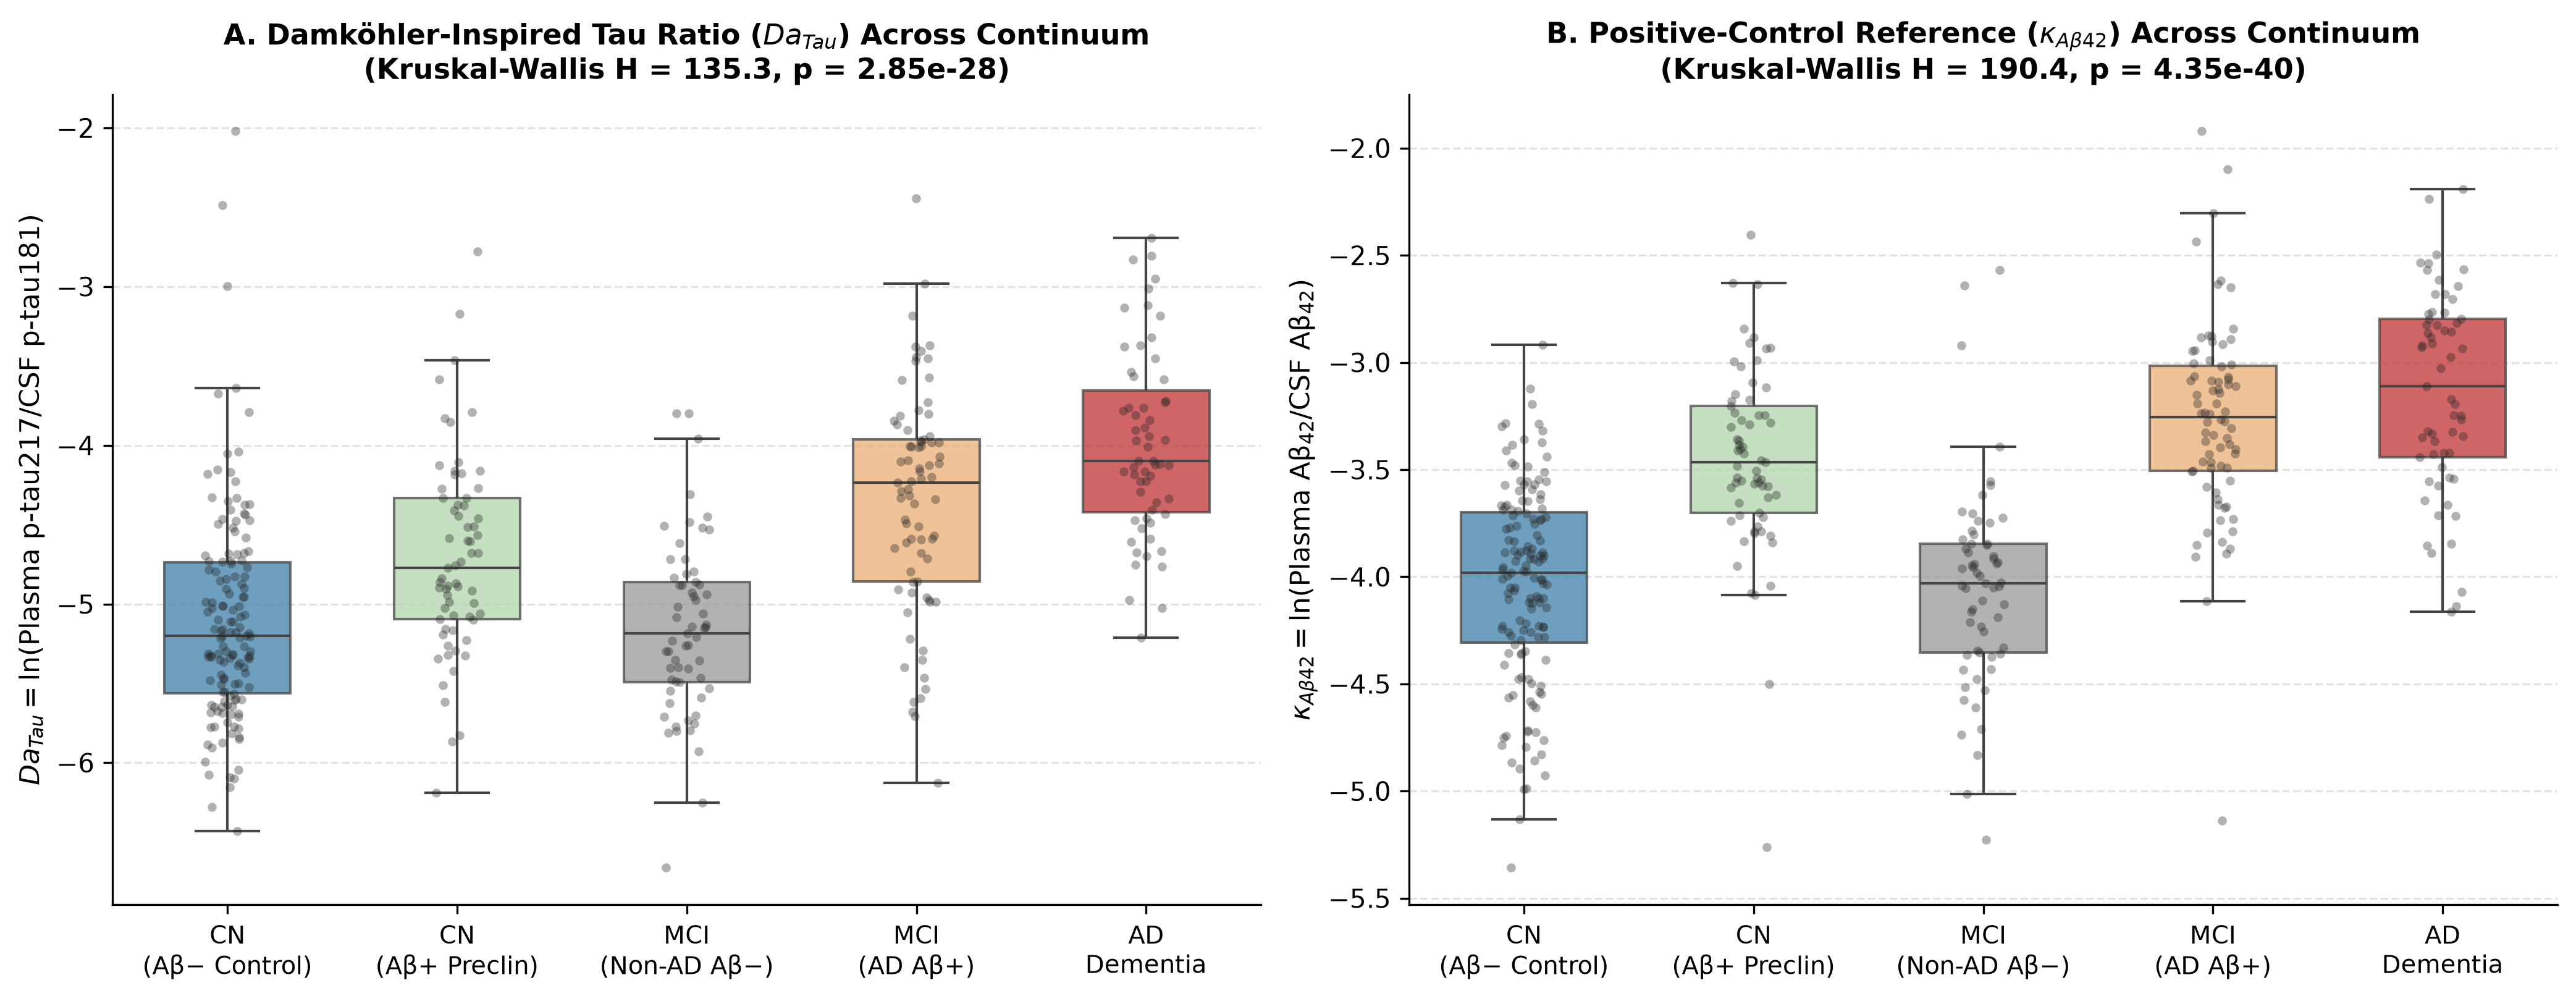

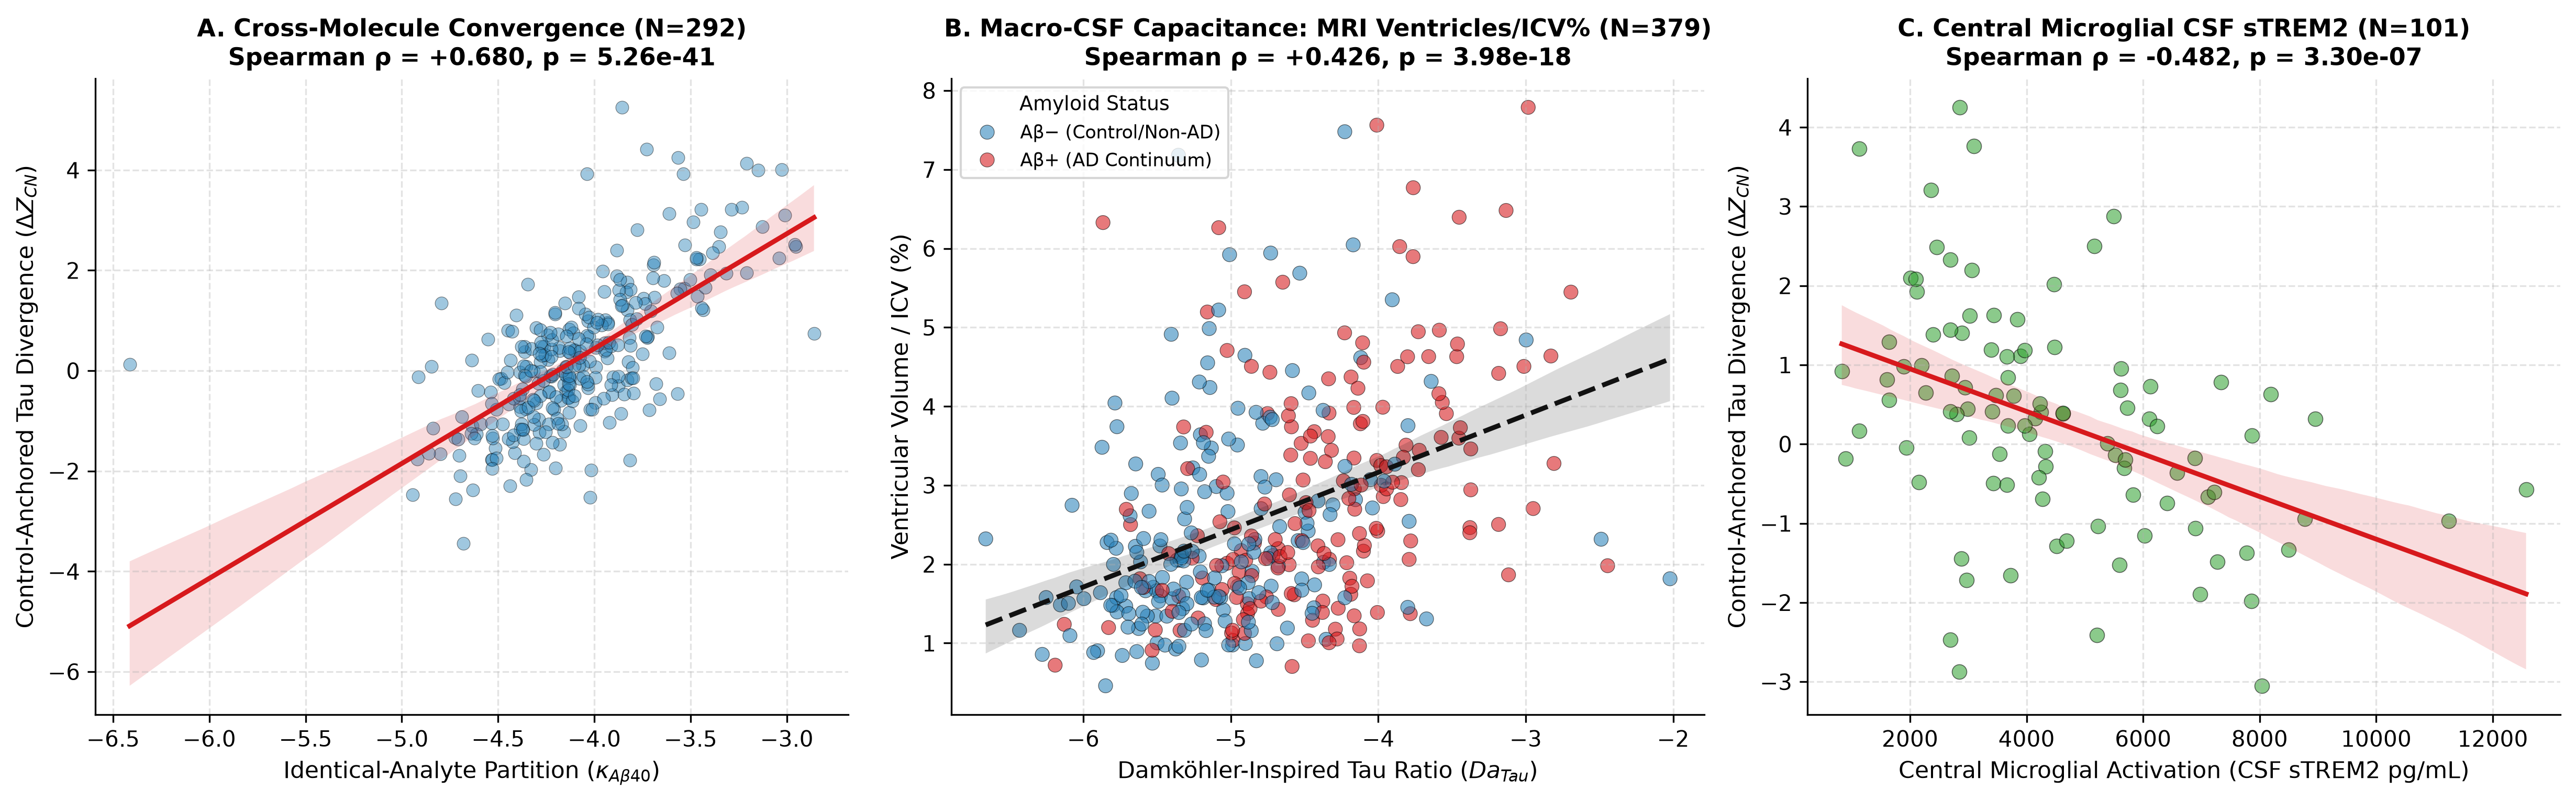

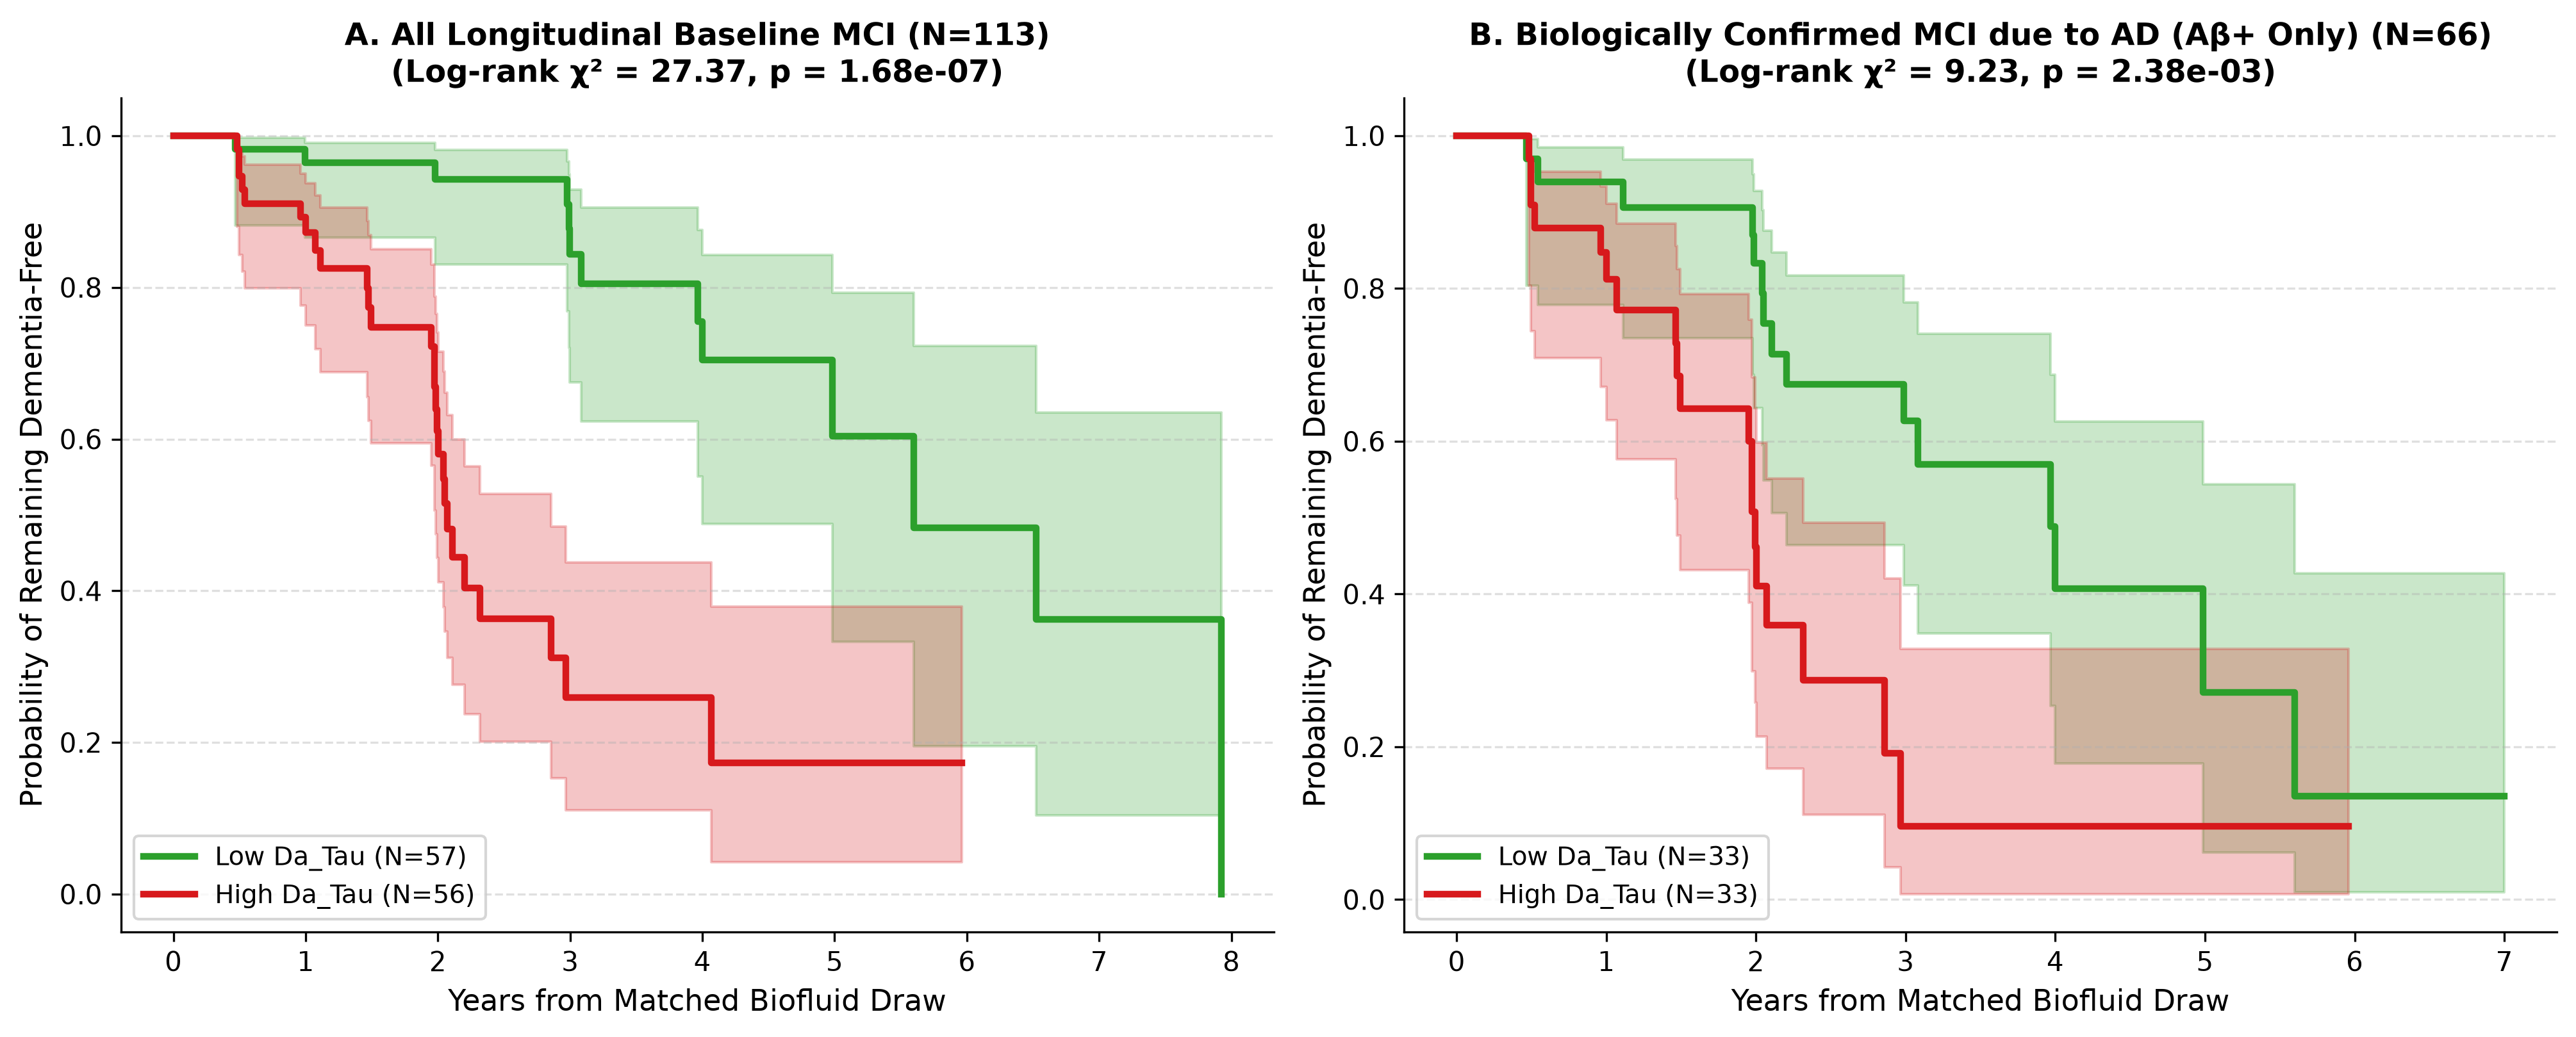

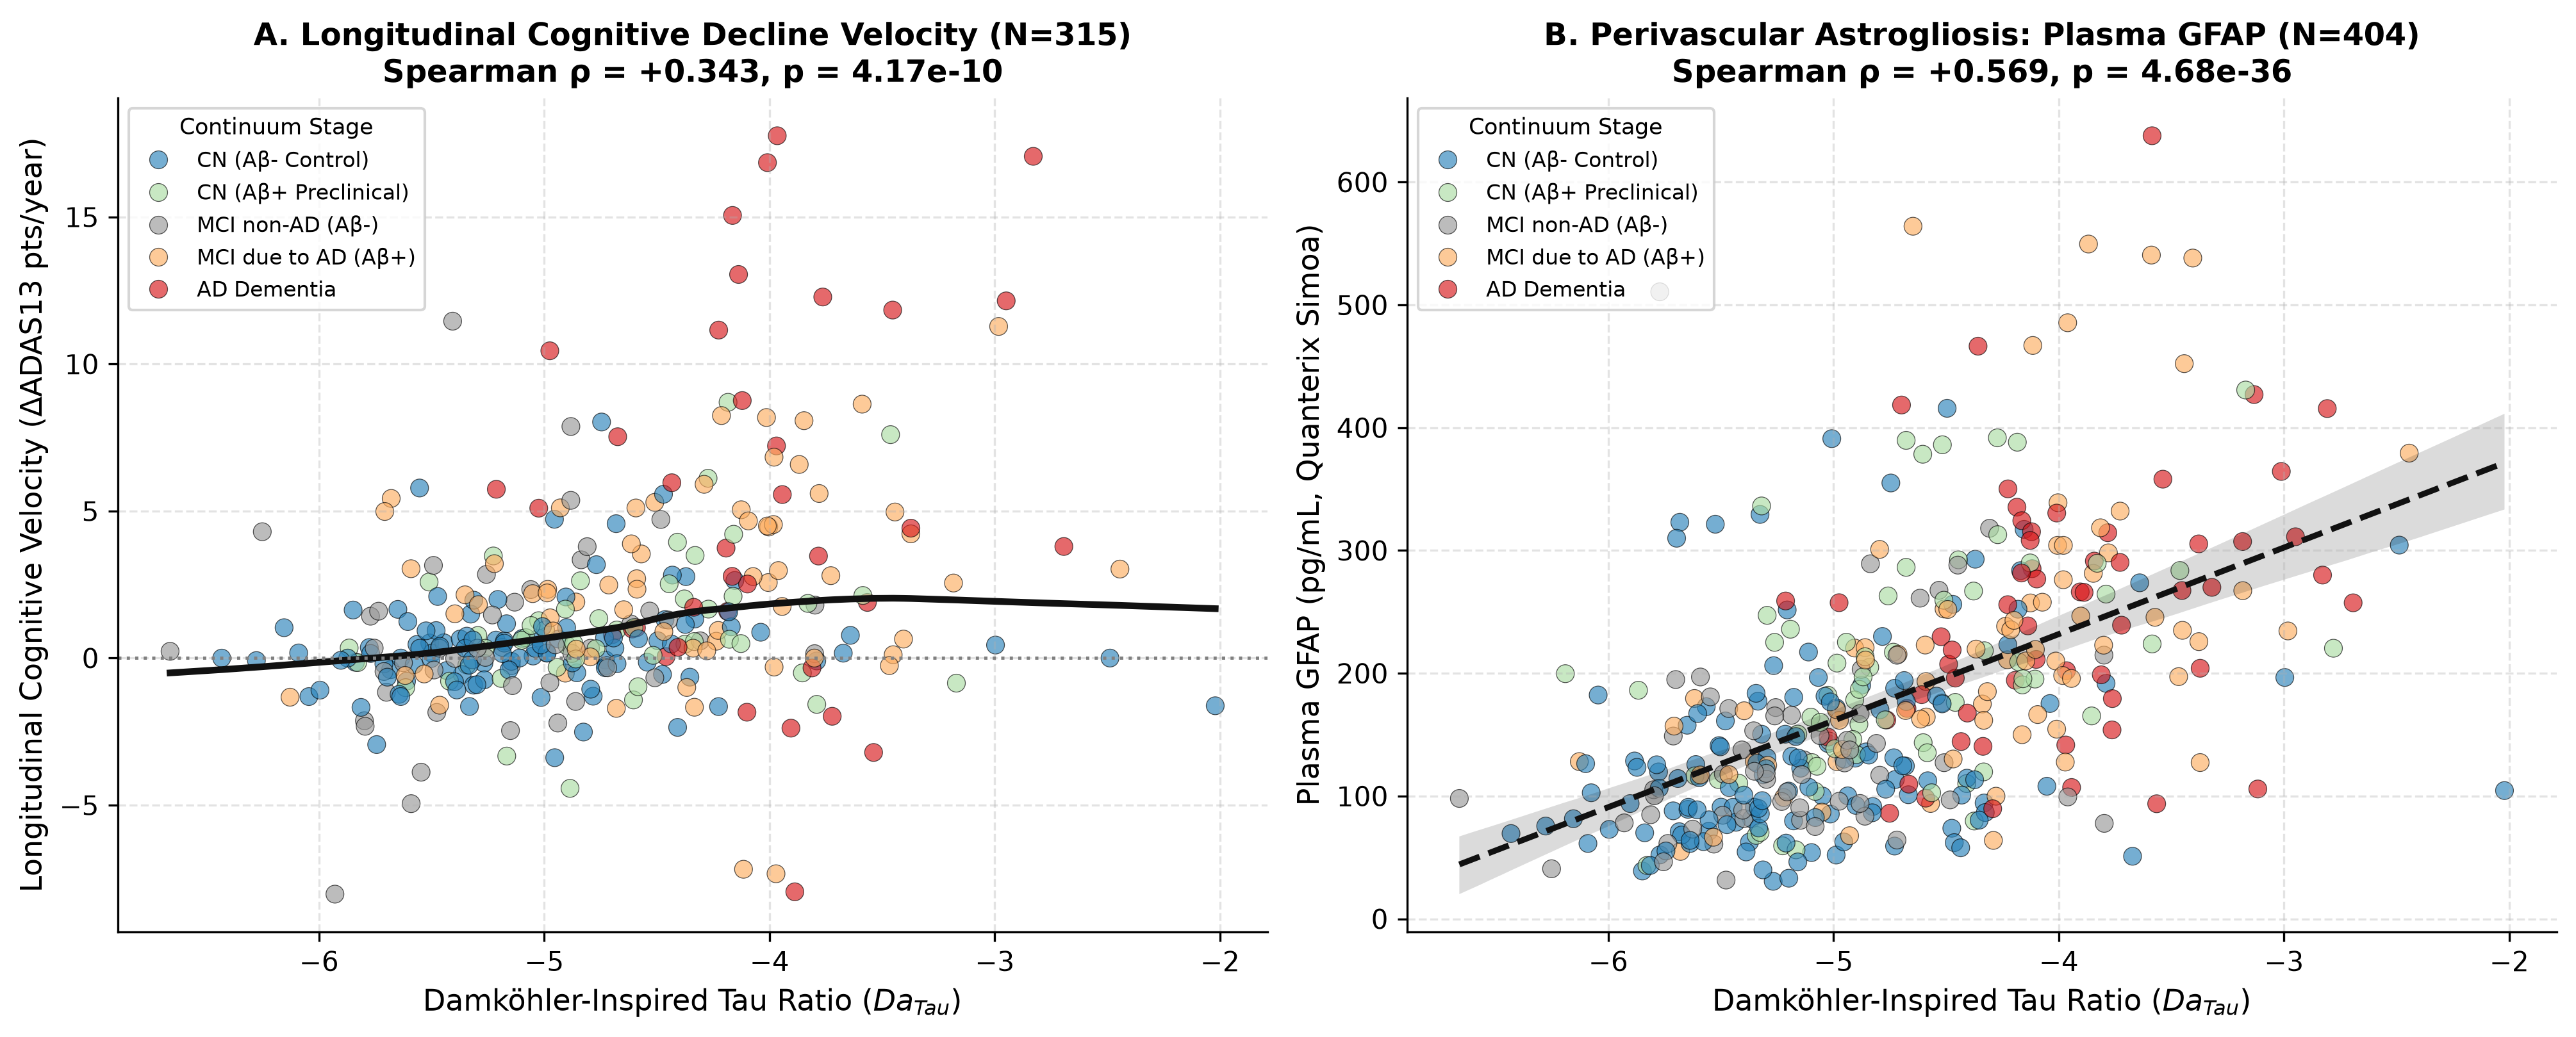

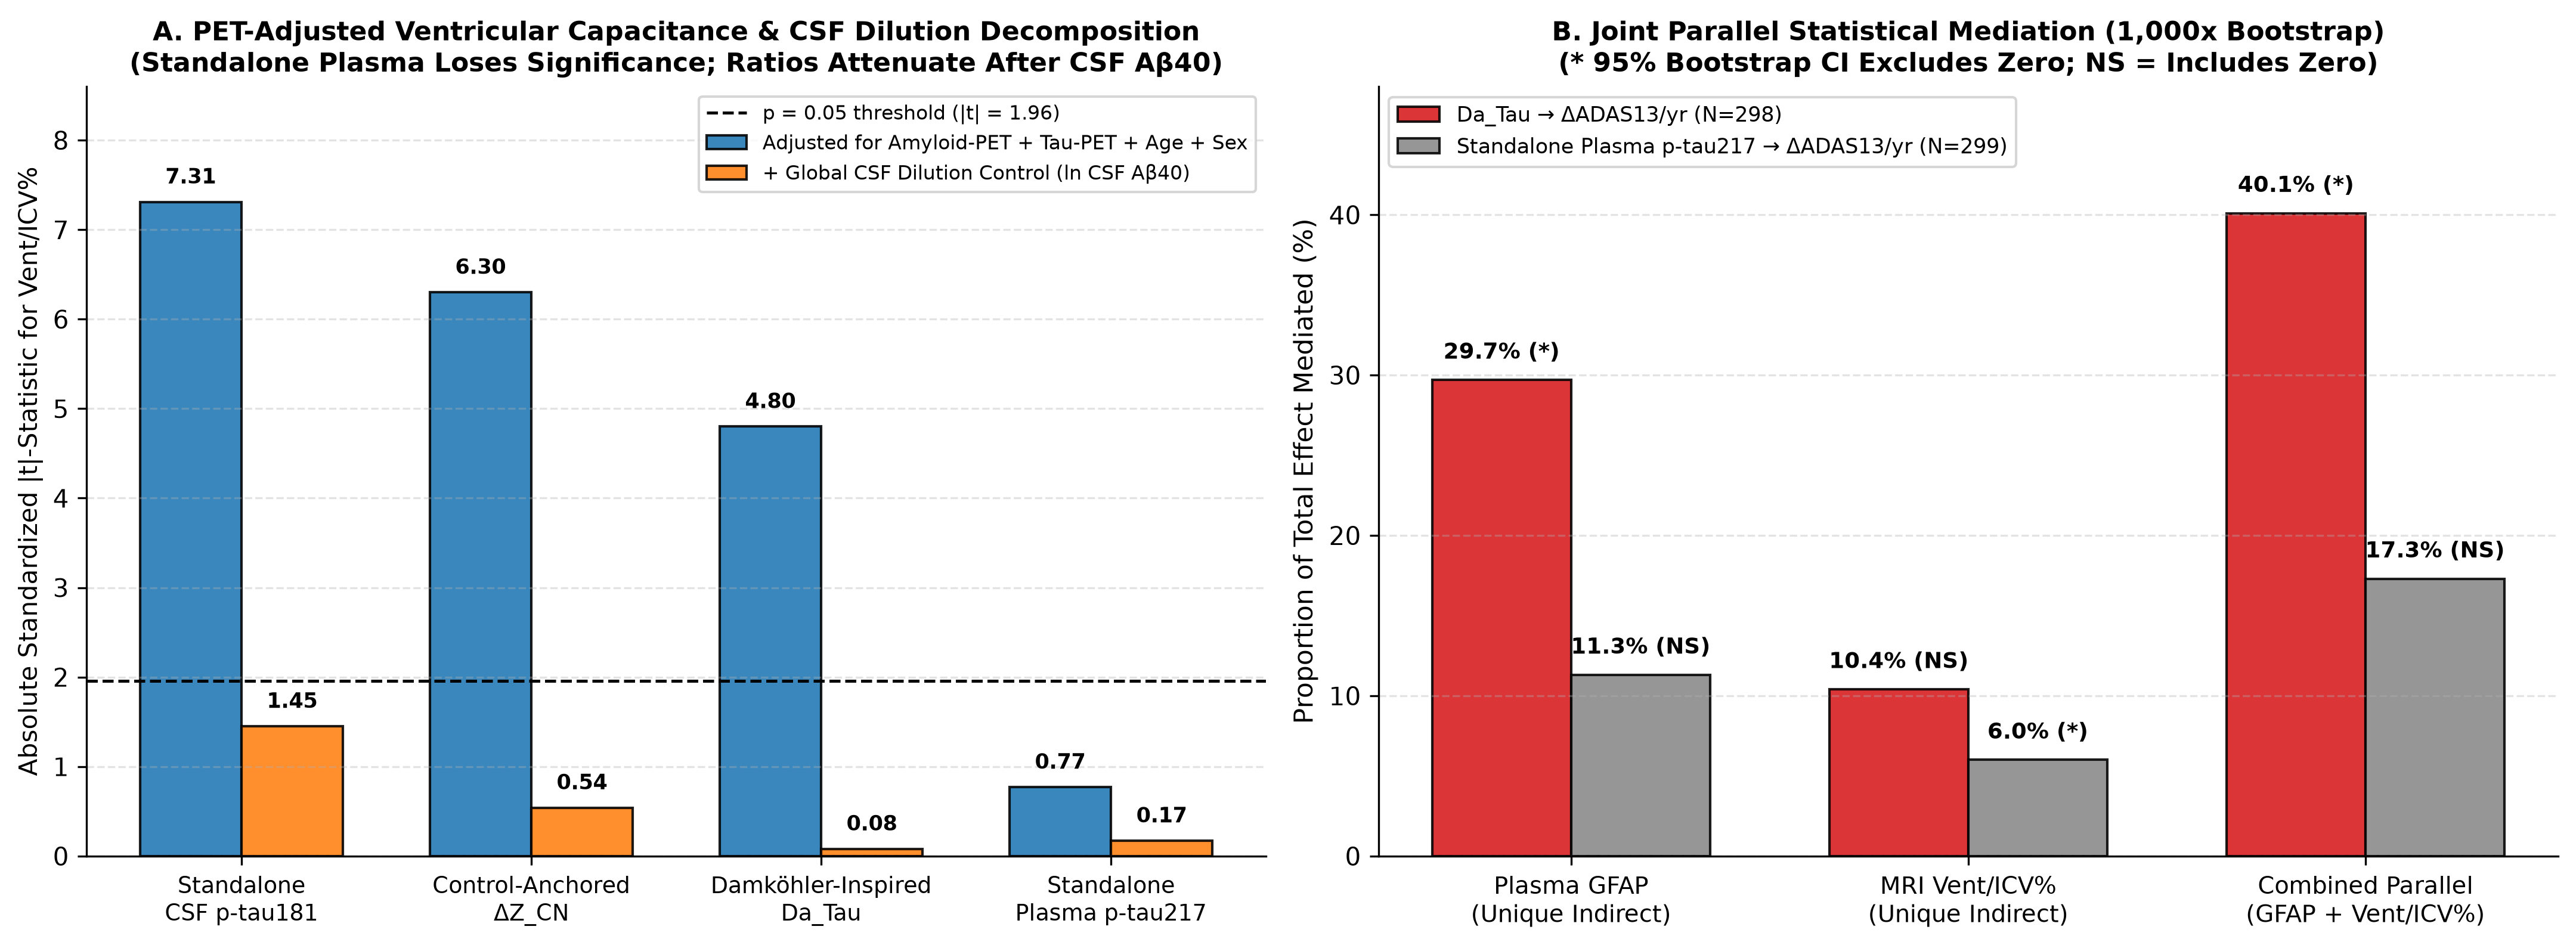

Synchronized exact plot N values: Fig2A= 292 Fig2B= 379 Fig2C= 101 Fig4A= 315 Fig4B= 404
Exact Fig2B rho=+0.426, p=3.98e-18 | Fig2C rho=-0.482, p=3.30e-07 | Fig4A rho=+0.343, p=4.17e-10 | Fig4B rho=+0.569, p=4.68e-36


In [6]:
# ------------------------------------------------------------------------------
# FIGURE 1: FULL ALZHEIMER'S CONTINUUM SPECIFICITY (Da_Tau & Positive-Control κ_Aβ42)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
palette = ['#2b83ba', '#abdda4', '#999999', '#fdae61', '#d7191c']
plot_df = df[df['Continuum_Group'].isin(order)].copy()

for ax, col, title, ylabel in [
    (axes[0], 'Da_Tau', r'A. Damköhler-Inspired Tau Ratio ($Da_{Tau}$) Across Continuum', r'$Da_{Tau} = \ln(\mathrm{Plasma\ p\text{-}tau217} / \mathrm{CSF\ p\text{-}tau181})$'),
    (axes[1], 'Kappa_AB42', r'B. Positive-Control Reference ($\kappa_{A\beta 42}$) Across Continuum', r'$\kappa_{A\beta 42} = \ln(\mathrm{Plasma\ A\beta_{42}} / \mathrm{CSF\ A\beta_{42}})$')
]:
    sns.boxplot(data=plot_df, x='Continuum_Group', y=col, order=order, palette=palette, showfliers=False, width=0.55, ax=ax, boxprops={'alpha':0.75})
    sns.stripplot(data=plot_df, x='Continuum_Group', y=col, order=order, color='#222222', alpha=0.35, size=3.5, jitter=True, ax=ax)
    groups = [plot_df[plot_df['Continuum_Group'] == g][col].dropna().values for g in order]
    h_stat, p_kw = kruskal(*groups)
    ax.set_title(f"{title}\n(Kruskal-Wallis H = {h_stat:.1f}, p = {p_kw:.2e})", fontsize=11, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=10.5)
    ax.set_xlabel('')
    ax.set_xticklabels(['CN\n(Aβ− Control)', 'CN\n(Aβ+ Preclin)', 'MCI\n(Non-AD Aβ−)', 'MCI\n(AD Aβ+)', 'AD\nDementia'], fontsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure1_Continuum_Specificity.png'), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 2: TRI-MODAL PHYSICAL & NEUROIMMUNE VALIDATION (FIXED RED/BLUE LEGEND!)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2), dpi=300)

# Panel A: Cross-Molecule Convergence (κ_Aβ40 vs ΔZ_CN)
s1 = df[['Kappa_AB40', 'DeltaZ_CN']].dropna()
r1, p1 = spearmanr(s1['Kappa_AB40'], s1['DeltaZ_CN'])
sns.regplot(data=s1, x='Kappa_AB40', y='DeltaZ_CN', scatter_kws={'alpha':0.45, 's':35, 'color':'#2b83ba', 'edgecolor':'k', 'linewidths':0.3}, line_kws={'color':'#d7191c', 'lw':2.2}, ax=axes[0])
axes[0].set_title(f"A. Cross-Molecule Convergence (N={len(s1)})\nSpearman ρ = {r1:+.3f}, p = {p1:.2e}", fontsize=11, fontweight='bold')
axes[0].set_xlabel(r'Identical-Analyte Partition ($\kappa_{A\beta 40}$)', fontsize=10.5)
axes[0].set_ylabel(r'Control-Anchored Tau Divergence ($\Delta Z_{CN}$)', fontsize=10.5)
axes[0].grid(True, linestyle='--', alpha=0.35)

# Panel B: MRI Ventricular Capacitance (Vent/ICV%) vs Da_Tau (EXACT COLOR-MATCHED LEGEND!)
s2 = df[['Da_Tau', 'Ventricular_ICV_Pct', 'Amyloid_Pos']].dropna().copy()
s2['Amyloid_Label'] = np.where(s2['Amyloid_Pos'], 'Aβ+ (AD Continuum)', 'Aβ− (Control/Non-AD)')
r2, p2 = spearmanr(s2['Da_Tau'], s2['Ventricular_ICV_Pct'])
sns.scatterplot(data=s2, x='Da_Tau', y='Ventricular_ICV_Pct', hue='Amyloid_Label',
                hue_order=['Aβ− (Control/Non-AD)', 'Aβ+ (AD Continuum)'],
                palette={'Aβ− (Control/Non-AD)':'#2b83ba', 'Aβ+ (AD Continuum)':'#d7191c'},
                alpha=0.58, s=42, edgecolor='k', linewidth=0.3, ax=axes[1])
sns.regplot(data=s2, x='Da_Tau', y='Ventricular_ICV_Pct', scatter=False, line_kws={'color':'#111111', 'lw':2.2, 'ls':'--'}, ax=axes[1])
axes[1].set_title(f"B. Macro-CSF Capacitance: MRI Ventricles/ICV% (N={len(s2)})\nSpearman ρ = {r2:+.3f}, p = {p2:.2e}", fontsize=11, fontweight='bold')
axes[1].set_xlabel(r'Damköhler-Inspired Tau Ratio ($Da_{Tau}$)', fontsize=10.5)
axes[1].set_ylabel('Ventricular Volume / ICV (%)', fontsize=10.5)
axes[1].legend(title='Amyloid Status', fontsize=8.5, title_fontsize=9, loc='upper left')
axes[1].grid(True, linestyle='--', alpha=0.35)

# Panel C: Microglial CSF sTREM2 vs ΔZ_CN
s3 = df[['sTREM2_CSF', 'DeltaZ_CN']].dropna()
r3, p3 = spearmanr(s3['sTREM2_CSF'], s3['DeltaZ_CN'])
sns.regplot(data=s3, x='sTREM2_CSF', y='DeltaZ_CN', scatter_kws={'alpha':0.55, 's':45, 'color':'#2ca02c', 'edgecolor':'k', 'linewidths':0.4}, line_kws={'color':'#d7191c', 'lw':2.2}, ax=axes[2])
axes[2].set_title(f"C. Central Microglial CSF sTREM2 (N={len(s3)})\nSpearman ρ = {r3:+.3f}, p = {p3:.2e}", fontsize=11, fontweight='bold')
axes[2].set_xlabel('Central Microglial Activation (CSF sTREM2 pg/mL)', fontsize=10.5)
axes[2].set_ylabel(r'Control-Anchored Tau Divergence ($\Delta Z_{CN}$)', fontsize=10.5)
axes[2].grid(True, linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure2_TriModal_Physical_Validation.png'), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 3: UNADJUSTED KAPLAN-MEIER SURVIVAL IN MCI
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=300)
for ax, sub_s, title in [
    (axes[0], mci_df.dropna(subset=['Da_Tau', 'Time', 'Event']), 'A. All Longitudinal Baseline MCI'),
    (axes[1], mci_df[mci_df['Amyloid_Pos'] == True].dropna(subset=['Da_Tau', 'Time', 'Event']), 'B. Biologically Confirmed MCI due to AD (Aβ+ Only)')
]:
    med = sub_s['Da_Tau'].median()
    low_da, high_da = sub_s['Da_Tau'] <= med, sub_s['Da_Tau'] > med
    lr = logrank_test(sub_s[low_da]['Time'], sub_s[high_da]['Time'], sub_s[low_da]['Event'], sub_s[high_da]['Event'])
    kmf_l, kmf_h = KaplanMeierFitter(), KaplanMeierFitter()
    kmf_l.fit(sub_s[low_da]['Time'], sub_s[low_da]['Event'], label=f'Low Da_Tau (N={low_da.sum()})')
    kmf_h.fit(sub_s[high_da]['Time'], sub_s[high_da]['Event'], label=f'High Da_Tau (N={high_da.sum()})')
    kmf_l.plot_survival_function(ax=ax, color='#2ca02c', lw=2.5)
    kmf_h.plot_survival_function(ax=ax, color='#d7191c', lw=2.5)
    ax.set_title(f"{title} (N={len(sub_s)})\n(Log-rank χ² = {lr.test_statistic:.2f}, p = {lr.p_value:.2e})", fontsize=11.5, fontweight='bold')
    ax.set_xlabel('Years from Matched Biofluid Draw', fontsize=11)
    ax.set_ylabel('Probability of Remaining Dementia-Free', fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=9.5)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure3_AD_Specific_Survival.png'), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 4: LONGITUDINAL COGNITIVE VELOCITY (EXACT N SYNCHRONIZED!) & PLASMA GFAP
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=300)
s4 = df[['Da_Tau', 'ADAS13_Slope_Yr', 'Continuum_Group']].dropna()
s4 = s4[(s4['ADAS13_Slope_Yr'] > -10) & (s4['ADAS13_Slope_Yr'] < 20) & (s4['Continuum_Group'].isin(order))]
r4, p4 = spearmanr(s4['Da_Tau'], s4['ADAS13_Slope_Yr'])
sns.scatterplot(data=s4, x='Da_Tau', y='ADAS13_Slope_Yr', hue='Continuum_Group', hue_order=order, palette=palette, alpha=0.65, s=45, edgecolor='k', linewidth=0.3, ax=axes[0])
sns.regplot(data=s4, x='Da_Tau', y='ADAS13_Slope_Yr', scatter=False, lowess=True, line_kws={'color':'#111111', 'lw':2.5}, ax=axes[0])
axes[0].axhline(0, color='gray', ls=':', lw=1.2)
axes[0].set_title(f"A. Longitudinal Cognitive Decline Velocity (N={len(s4)})\nSpearman ρ = {r4:+.3f}, p = {p4:.2e}", fontsize=11.5, fontweight='bold')
axes[0].set_xlabel(r'Damköhler-Inspired Tau Ratio ($Da_{Tau}$)', fontsize=11)
axes[0].set_ylabel('Longitudinal Cognitive Velocity (ΔADAS13 pts/year)', fontsize=11)
axes[0].legend(title='Continuum Stage', fontsize=8, title_fontsize=8.5, loc='upper left')
axes[0].grid(True, linestyle='--', alpha=0.35)

s5 = df[['Da_Tau', 'GFAP_Q_clean', 'Continuum_Group']].dropna()
s5 = s5[s5['Continuum_Group'].isin(order)]
r5, p5 = spearmanr(s5['Da_Tau'], s5['GFAP_Q_clean'])
sns.scatterplot(data=s5, x='Da_Tau', y='GFAP_Q_clean', hue='Continuum_Group', hue_order=order, palette=palette, alpha=0.65, s=45, edgecolor='k', linewidth=0.3, ax=axes[1])
sns.regplot(data=s5, x='Da_Tau', y='GFAP_Q_clean', scatter=False, line_kws={'color':'#111111', 'lw':2.2, 'ls':'--'}, ax=axes[1])
axes[1].set_title(f"B. Perivascular Astrogliosis: Plasma GFAP (N={len(s5)})\nSpearman ρ = {r5:+.3f}, p = {p5:.2e}", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel(r'Damköhler-Inspired Tau Ratio ($Da_{Tau}$)', fontsize=11)
axes[1].set_ylabel('Plasma GFAP (pg/mL, Quanterix Simoa)', fontsize=11)
axes[1].legend(title='Continuum Stage', fontsize=8, title_fontsize=8.5, loc='upper left')
axes[1].grid(True, linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure4_Longitudinal_Velocity_and_GFAP.png'), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 5: CSF DILUTION DECOMPOSITION (PANEL A) & JOINT PARALLEL MEDIATION (PANEL B)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), dpi=300)

# Panel A: Absolute |t|-statistics for Vent/ICV% (PET-Adjusted vs + ln CSF Aβ40 Dilution Control)
labels_5a = ['Standalone\nCSF p-tau181', 'Control-Anchored\nΔZ_CN', 'Damköhler-Inspired\nDa_Tau', 'Standalone\nPlasma p-tau217']
t_pet  = [7.31, 6.30, 4.80, 0.77]
t_dil  = [1.45, 0.54, 0.08, 0.17]
x_pos  = np.arange(len(labels_5a))
w = 0.35
b1 = axes[0].bar(x_pos - w/2, t_pet, width=w, color='#1f77b4', edgecolor='k', alpha=0.88, label='Adjusted for Amyloid-PET + Tau-PET + Age + Sex')
b2 = axes[0].bar(x_pos + w/2, t_dil, width=w, color='#ff7f0e', edgecolor='k', alpha=0.88, label='+ Global CSF Dilution Control (ln CSF Aβ40)')
axes[0].axhline(1.96, color='black', ls='--', lw=1.2, label='p = 0.05 threshold (|t| = 1.96)')
for bar, val in zip(b1, t_pet):
    axes[0].text(bar.get_x()+bar.get_width()/2, val+0.15, f"{val:.2f}", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
for bar, val in zip(b2, t_dil):
    axes[0].text(bar.get_x()+bar.get_width()/2, val+0.15, f"{val:.2f}", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels_5a, fontsize=9.2)
axes[0].set_ylabel('Absolute Standardized |t|-Statistic for Vent/ICV%', fontsize=10)
axes[0].set_ylim(0, 8.6)
axes[0].set_title('A. PET-Adjusted Ventricular Capacitance & CSF Dilution Decomposition\n(Standalone Plasma Loses Significance; Ratios Attenuate After CSF Aβ40)', fontsize=10.5, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=8)
axes[0].grid(axis='y', linestyle='--', alpha=0.35)

# Panel B: Joint Parallel Statistical Mediation (Da_Tau vs Standalone Plasma p-tau217)
m_labels = ['Plasma GFAP\n(Unique Indirect)', 'MRI Vent/ICV%\n(Unique Indirect)', 'Combined Parallel\n(GFAP + Vent/ICV%)']
da_pcts = [med_df.loc[0, 'GFAP_pct'], med_df.loc[0, 'Vent_pct'], med_df.loc[0, 'Comb_pct']]
pl_pcts = [med_df.loc[1, 'GFAP_pct'], med_df.loc[1, 'Vent_pct'], med_df.loc[1, 'Comb_pct']]
x_m = np.arange(len(m_labels))
bm1 = axes[1].bar(x_m - w/2, da_pcts, width=w, color='#d7191c', edgecolor='k', alpha=0.88, label='Da_Tau → ΔADAS13/yr (N=298)')
bm2 = axes[1].bar(x_m + w/2, pl_pcts, width=w, color='#888888', edgecolor='k', alpha=0.88, label='Standalone Plasma p-tau217 → ΔADAS13/yr (N=299)')
for bar, val, sig in zip(bm1, da_pcts, ['*', 'NS', '*']):
    axes[1].text(bar.get_x()+bar.get_width()/2, val+1.0, f"{val:.1f}% ({sig})", ha='center', va='bottom', fontsize=8.8, fontweight='bold')
for bar, val, sig in zip(bm2, pl_pcts, ['NS', '*', 'NS']):
    axes[1].text(bar.get_x()+bar.get_width()/2, val+1.0, f"{val:.1f}% ({sig})", ha='center', va='bottom', fontsize=8.8, fontweight='bold')
axes[1].set_xticks(x_m)
axes[1].set_xticklabels(m_labels, fontsize=9.5)
axes[1].set_ylabel('Proportion of Total Effect Mediated (%)', fontsize=10.5)
axes[1].set_ylim(0, 48)
axes[1].set_title('B. Joint Parallel Statistical Mediation (1,000x Bootstrap)\n(* 95% Bootstrap CI Excludes Zero; NS = Includes Zero)', fontsize=10.5, fontweight='bold')
axes[1].legend(loc='upper left', fontsize=8.5)
axes[1].grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Figure5_Dilution_Decomposition_and_Mediation.png'), dpi=300)
plt.show()
print("Synchronized exact plot N values: Fig2A=", len(s1), "Fig2B=", len(s2), "Fig2C=", len(s3), "Fig4A=", len(s4), "Fig4B=", len(s5))
print(f"Exact Fig2B rho={r2:+.3f}, p={p2:.2e} | Fig2C rho={r3:+.3f}, p={p3:.2e} | Fig4A rho={r4:+.3f}, p={p4:.2e} | Fig4B rho={r5:+.3f}, p={p5:.2e}")
